In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Datasets

In [69]:
account_master = pd.read_csv("account_master.csv")
churned_labeled = pd.read_csv("churned_labeled.csv")
churned_to_predict = pd.read_csv("churned_to_predict.csv")
support_tickets = pd.read_csv("support_tickets.csv")
usage_logs = pd.read_csv("usage_logs.csv")

## chack dataset shapes

In [70]:
print("Account Master:", account_master.shape)
print("Usage Logs:", usage_logs.shape)
print("Support Tickets:", support_tickets.shape)
print("Churned Labeled:", churned_labeled.shape)
print("Churned To Predict:", churned_to_predict.shape)

Account Master: (444, 5)
Usage Logs: (5339, 5)
Support Tickets: (1388, 5)
Churned Labeled: (378, 2)
Churned To Predict: (66, 1)


## Inspect datasets

In [71]:
print("----ACCOUNT MASTER----")
display(account_master.head())

print("\n----USAGE LOGS----")
display(usage_logs.head())

print("\n----SUPPORT TICKETS----")
display(support_tickets.head())

print("\n----CHURNED LABELED----")
display(churned_labeled.head())

print("\n----CHURNED TO PREDICT----")
display(churned_to_predict.head())

----ACCOUNT MASTER----


,account_id,plan_tier,tenure_months,region,referral_source
0,CUST-0001,Free,22,EU,Paid Ads
1,CUST-0002,Free,45,LATAM,Organic
2,CUST-0003,Business,7,NaN,Partner
3,CUST-0004,Free,59,NaN,Paid Ads
4,CUST-0005,Free,33,APAC,Partner



----USAGE LOGS----


,record_id,account_id,log_date,logins_per_week,feature_usage_score
0,USA-004124,CUST-0345,2023-07-03,2.326100,3.163764
1,USA-003239,CUST-0271,2023-11-16,3.544125,4.912016
2,USA-000302,CUST-0026,2024-02-03,2.603275,2.425066
3,USA-002293,CUST-0194,2023-08-16,4.195689,4.008846
4,USA-004521,CUST-0380,2024-02-08,7.269028,4.874792



----SUPPORT TICKETS----


,record_id,account_id,ticket_date,issue_category,resolution_time_hours
0,SUP-001136,CUST-0361,2024-06-12,Bug,1.603192
1,SUP-000089,CUST-0034,2023-12-06,Feature Request,17.449264
2,SUP-000003,CUST-0002,2024-04-28,Bug,5.133836
3,SUP-001082,CUST-0348,2023-08-31,Bug,3.907318
4,SUP-000747,CUST-0244,2023-09-15,Feature Request,19.211250



----CHURNED LABELED----


,account_id,churned
0,CUST-0001,No
1,CUST-0002,No
2,CUST-0003,No
3,CUST-0004,Yes
4,CUST-0005,Yes



----CHURNED TO PREDICT----


,account_id
0,CUST-0009
1,CUST-0014
2,CUST-0017
3,CUST-0038
4,CUST-0043


## Information

In [72]:
print("--- ACCOUNT MASTER INFO ---")
account_master.info()

print("\n--- USAGE LOGS INFO ---")
usage_logs.info()

print("\n--- SUPPORT TICKETS INFO ---")
support_tickets.info()

print("\n--- CHURNED LABELED INFO ---")
churned_labeled.info()

print("\n--- CHURNED TO PREDICT INFO ---")
churned_to_predict.info()

--- ACCOUNT MASTER INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 444 entries, 0 to 443
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   account_id       444 non-null    object
 1   plan_tier        444 non-null    object
 2   tenure_months    444 non-null    int64 
 3   region           328 non-null    object
 4   referral_source  427 non-null    object
dtypes: int64(1), object(4)
memory usage: 17.5+ KB

--- USAGE LOGS INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5339 entries, 0 to 5338
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   record_id            5339 non-null   object 
 1   account_id           5339 non-null   object 
 2   log_date             5339 non-null   object 
 3   logins_per_week      5339 non-null   float64
 4   feature_usage_score  5339 non-null   float64
dtypes: float64(2), o

## Checking missing values

In [73]:
print("--- MISSING VALUES ---")

print("\nAccount Master:")
print(account_master.isnull().sum())

print("\nUsage Logs:")
print(usage_logs.isnull().sum())

print("\nSupport Tickets:")
print(support_tickets.isnull().sum())

print("\nChurned Labeled:")
print(churned_labeled.isnull().sum())

print("\nChurned To Predict:")
print(churned_to_predict.isnull().sum())

--- MISSING VALUES ---

Account Master:
account_id           0
plan_tier            0
tenure_months        0
region             116
referral_source     17
dtype: int64

Usage Logs:
record_id              0
account_id             0
log_date               0
logins_per_week        0
feature_usage_score    0
dtype: int64

Support Tickets:
record_id                 0
account_id                0
ticket_date               0
issue_category            0
resolution_time_hours    25
dtype: int64

Churned Labeled:
account_id    0
churned       0
dtype: int64

Churned To Predict:
account_id    0
dtype: int64


## Check duplicates

In [74]:
print("--- DUPLICATED ROWS ---")

print("Account Master:", account_master.duplicated().sum())
print("Usage Logs:", usage_logs.duplicated().sum())
print("Support Tickets:", support_tickets.duplicated().sum())
print("Churned Labeled:", churned_labeled.duplicated().sum())
print("Churned To Predict:", churned_to_predict.duplicated().sum())

--- DUPLICATED ROWS ---
Account Master: 0
Usage Logs: 0
Support Tickets: 0
Churned Labeled: 0
Churned To Predict: 0


## check statstics in usage_logs

In [75]:
usage_logs[["logins_per_week", "feature_usage_score"]].describe()

,logins_per_week,feature_usage_score
count,5339.000000,5339.000000
mean,6.117388,5.060596
std,3.385106,1.607272
min,-14.390894,0.000000
25%,3.887463,3.939827
50%,6.120626,5.024561
75%,8.202493,6.155208
max,27.661383,10.000000


## check login outliers

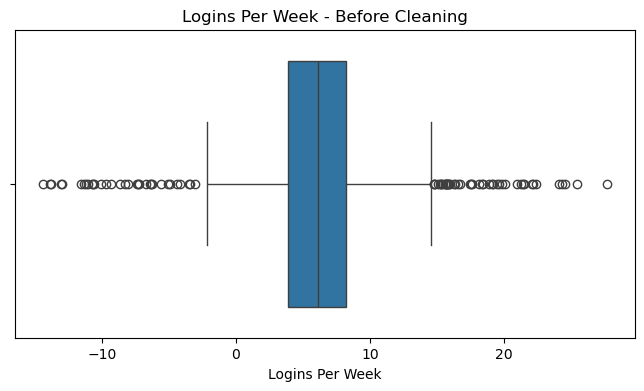

In [76]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=usage_logs["logins_per_week"])
plt.title("Logins Per Week - Before Cleaning")
plt.xlabel("Logins Per Week")
plt.show()

By checking statics we found that invalid values in logins_per_week,identify it

In [77]:
negative_login=usage_logs[usage_logs["logins_per_week"]<0]
print("Number of negative login records:",len(negative_login))

print("-----------------------------------------------------------------")

display(negative_login[[
    "account_id","log_date","logins_per_week","feature_usage_score"
]].head(10))

Number of negative login records: 37
-----------------------------------------------------------------


,account_id,log_date,logins_per_week,feature_usage_score
14,CUST-0096,2023-06-09,-9.304708,4.165896
181,CUST-0407,2023-09-04,-3.510287,6.458982
210,CUST-0084,2024-04-05,-3.067856,6.808331
329,CUST-0290,2024-05-02,-11.013420,4.948505
377,CUST-0271,2023-10-13,-6.734847,4.145395
413,CUST-0342,2023-12-19,-8.301889,3.036488
575,CUST-0087,2023-11-04,-4.196464,7.434870
669,CUST-0311,2023-12-21,-0.894675,6.420066
858,CUST-0267,2024-02-06,-4.382498,3.321678
999,CUST-0064,2024-03-02,-7.239407,4.019430


## Remove invalid negative values

In [78]:
usage_logs=usage_logs[usage_logs["logins_per_week"]>=0].copy()

print("usage logs after removing negatives values:",usage_logs.shape)

usage logs after removing negatives values: (5302, 5)


## after checking again outlier -removed invalid values

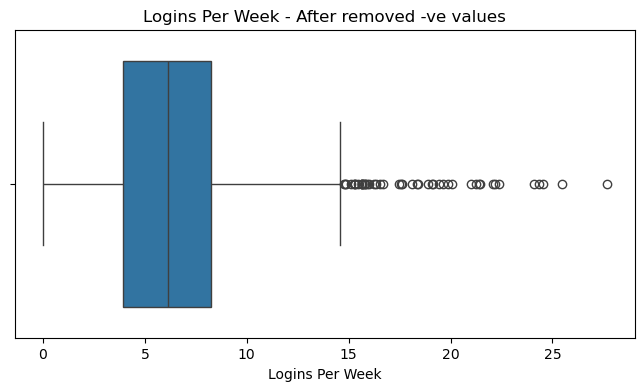

In [79]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=usage_logs["logins_per_week"])
plt.title("Logins Per Week - After removed -ve values")
plt.xlabel("Logins Per Week")
plt.show()

## calucate IQR and count outliers

In [80]:
Q1 = usage_logs["logins_per_week"].quantile(0.25)
Q3 = usage_logs["logins_per_week"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 3.9450609197586695
Q3: 8.218501642216546
IQR: 4.273440722457877
Lower Bound: -2.4651001639281467
Upper Bound: 14.628662725903363


In [81]:
outliers = usage_logs[
    (usage_logs["logins_per_week"] < lower_bound) |
    (usage_logs["logins_per_week"] > upper_bound)
]

print("Number of outliers:", len(outliers))

Number of outliers: 46


## handle outliers using IQR capping

In [82]:
usage_logs["logins_per_week"] = usage_logs[
    "logins_per_week"
].clip(
    upper=upper_bound
)

In [83]:
print("Maximum login value after capping:",
      usage_logs["logins_per_week"].max())

print("Minimum login value after capping:",
      usage_logs["logins_per_week"].min())

Maximum login value after capping: 14.628662725903363
Minimum login value after capping: 0.0


## After doing outlier

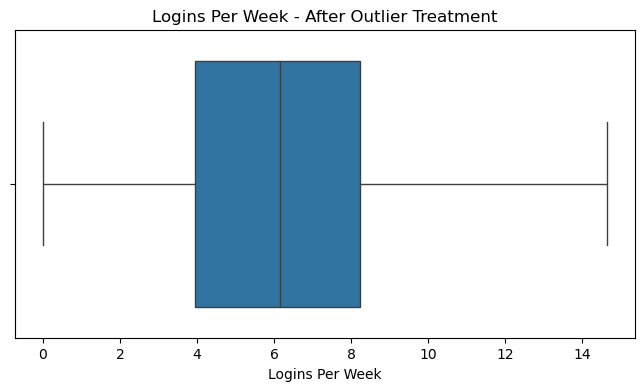

In [84]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=usage_logs["logins_per_week"]
)

plt.title("Logins Per Week - After Outlier Treatment")
plt.xlabel("Logins Per Week")

plt.show()

## Aggregate usage logs

In [85]:
usage_features=usage_logs.groupby("account_id").agg(
    avg_login_per_week=("logins_per_week","mean"),
    avg_feature_usage_score=("feature_usage_score","mean"),
    record_usage_count=("record_id","count")
).reset_index()

In [86]:
print("Usage features shape:", usage_features.shape)
display(usage_features.head())

Usage features shape: (444, 4)


,account_id,avg_login_per_week,avg_feature_usage_score,record_usage_count
0,CUST-0001,9.331482,6.160007,11
1,CUST-0002,6.813191,5.798467,9
2,CUST-0003,1.890863,3.070362,17
3,CUST-0004,0.883542,2.693287,11
4,CUST-0005,3.534468,3.965478,14


## check missing values in support tickets

In [87]:
support_tickets["resolution_time_hours"].describe()

count    1363.000000
mean       12.530183
std         8.532886
min         0.500000
25%         5.533987
50%        12.129673
75%        18.565616
max        43.725028
Name: resolution_time_hours, dtype: float64

In [88]:
print("Missing resolution time:",support_tickets["resolution_time_hours"].isnull().sum())

Missing resolution time: 25


In [89]:
#calculte the median
median_resol=support_tickets["resolution_time_hours"].median()
print("Median resolution time hours:",median_resol)

Median resolution time hours: 12.12967302486993


In [90]:
#fill the missing values with median
support_tickets["resolution_time_hours"]=support_tickets["resolution_time_hours"].fillna(median_resol)

In [91]:
print("missing resolution time after fill median:",support_tickets["resolution_time_hours"].isnull().sum())

missing resolution time after fill median: 0


## Aggregate support_tickets

In [92]:
support_features=support_tickets.groupby("account_id").agg(
    ticket_count=("record_id","count"),
    avg_resolution_time=("resolution_time_hours","mean")
).reset_index()

In [93]:
print("Support features shape:", support_features.shape)
display(support_features.head())

Support features shape: (383, 3)


,account_id,ticket_count,avg_resolution_time
0,CUST-0001,3,11.414820
1,CUST-0002,1,5.133836
2,CUST-0003,3,11.190170
3,CUST-0004,1,25.240915
4,CUST-0005,2,24.967414


In [94]:
print(support_features.isnull().sum())

account_id             0
ticket_count           0
avg_resolution_time    0
dtype: int64


## Merging

In [95]:
merge_data = account_master.merge(
    usage_features,
    on="account_id",
    how="left"
)

In [96]:
print("After merging account and usage:")
print(merge_data.shape)

display(merge_data.head())

After merging account and usage:
(444, 8)


,account_id,plan_tier,tenure_months,region,referral_source,avg_login_per_week,avg_feature_usage_score,record_usage_count
0,CUST-0001,Free,22,EU,Paid Ads,9.331482,6.160007,11
1,CUST-0002,Free,45,LATAM,Organic,6.813191,5.798467,9
2,CUST-0003,Business,7,NaN,Partner,1.890863,3.070362,17
3,CUST-0004,Free,59,NaN,Paid Ads,0.883542,2.693287,11
4,CUST-0005,Free,33,APAC,Partner,3.534468,3.965478,14


In [97]:
merge_data = merge_data.merge(
    support_features,
    on="account_id",
    how="left"
)

In [98]:
print("After merging support features:")
print(merge_data.shape)

display(merge_data.head())

After merging support features:
(444, 10)


,account_id,plan_tier,tenure_months,region,referral_source,avg_login_per_week,avg_feature_usage_score,record_usage_count,ticket_count,avg_resolution_time
0,CUST-0001,Free,22,EU,Paid Ads,9.331482,6.160007,11,3.0,11.414820
1,CUST-0002,Free,45,LATAM,Organic,6.813191,5.798467,9,1.0,5.133836
2,CUST-0003,Business,7,NaN,Partner,1.890863,3.070362,17,3.0,11.190170
3,CUST-0004,Free,59,NaN,Paid Ads,0.883542,2.693287,11,1.0,25.240915
4,CUST-0005,Free,33,APAC,Partner,3.534468,3.965478,14,2.0,24.967414


## Merge with churn labels

In [99]:
merge_data = merge_data.merge(
    churned_labeled,
    on="account_id",
    how="inner"
)

In [100]:
print("Final merged dataset shape:")
print(merge_data.shape)

display(merge_data.head())

Final merged dataset shape:
(378, 11)


,account_id,plan_tier,tenure_months,region,referral_source,avg_login_per_week,avg_feature_usage_score,record_usage_count,ticket_count,avg_resolution_time,churned
0,CUST-0001,Free,22,EU,Paid Ads,9.331482,6.160007,11,3.0,11.414820,No
1,CUST-0002,Free,45,LATAM,Organic,6.813191,5.798467,9,1.0,5.133836,No
2,CUST-0003,Business,7,NaN,Partner,1.890863,3.070362,17,3.0,11.190170,No
3,CUST-0004,Free,59,NaN,Paid Ads,0.883542,2.693287,11,1.0,25.240915,Yes
4,CUST-0005,Free,33,APAC,Partner,3.534468,3.965478,14,2.0,24.967414,Yes


## checking missing values after merging

In [101]:
print("--- Missing Values After Merging ---")

print(merge_data.isnull().sum())

--- Missing Values After Merging ---
account_id                   0
plan_tier                    0
tenure_months                0
region                     100
referral_source             14
avg_login_per_week           0
avg_feature_usage_score      0
record_usage_count           0
ticket_count                52
avg_resolution_time         52
churned                      0
dtype: int64


In [102]:
merge_data["region"] = merge_data[
    "region"
].fillna("Unknown")

merge_data["referral_source"] = merge_data[
    "referral_source"
].fillna("Unknown")

merge_data["ticket_count"] = merge_data[
    "ticket_count"
].fillna(0)


In [103]:
median_resolution = merge_data[
    "avg_resolution_time"
].median()

merge_data["avg_resolution_time"] = merge_data[
    "avg_resolution_time"
].fillna(
    median_resolution
)

In [104]:
#after checking
print(merge_data.isnull().sum())

account_id                 0
plan_tier                  0
tenure_months              0
region                     0
referral_source            0
avg_login_per_week         0
avg_feature_usage_score    0
record_usage_count         0
ticket_count               0
avg_resolution_time        0
churned                    0
dtype: int64


### checks duplicates in final data set

In [105]:
print("Duplicate rows:",merge_data.duplicated().sum())

Duplicate rows: 0


In [106]:
#check final data info
merge_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 378 entries, 0 to 377
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   account_id               378 non-null    object 
 1   plan_tier                378 non-null    object 
 2   tenure_months            378 non-null    int64  
 3   region                   378 non-null    object 
 4   referral_source          378 non-null    object 
 5   avg_login_per_week       378 non-null    float64
 6   avg_feature_usage_score  378 non-null    float64
 7   record_usage_count       378 non-null    int64  
 8   ticket_count             378 non-null    float64
 9   avg_resolution_time      378 non-null    float64
 10  churned                  378 non-null    object 
dtypes: float64(4), int64(2), object(5)
memory usage: 32.6+ KB


In [107]:
display(merge_data.head())

,account_id,plan_tier,tenure_months,region,referral_source,avg_login_per_week,avg_feature_usage_score,record_usage_count,ticket_count,avg_resolution_time,churned
0,CUST-0001,Free,22,EU,Paid Ads,9.331482,6.160007,11,3.0,11.414820,No
1,CUST-0002,Free,45,LATAM,Organic,6.813191,5.798467,9,1.0,5.133836,No
2,CUST-0003,Business,7,Unknown,Partner,1.890863,3.070362,17,3.0,11.190170,No
3,CUST-0004,Free,59,Unknown,Paid Ads,0.883542,2.693287,11,1.0,25.240915,Yes
4,CUST-0005,Free,33,APAC,Partner,3.534468,3.965478,14,2.0,24.967414,Yes


In [108]:
merge_data.describe()

,tenure_months,avg_login_per_week,avg_feature_usage_score,record_usage_count,ticket_count,avg_resolution_time
count,378.000000,378.000000,378.000000,378.000000,378.000000,378.000000
mean,31.968254,6.173223,5.058900,11.997354,3.082011,12.771161
std,17.434806,2.593064,1.298157,3.655960,2.025342,6.732216
min,1.000000,0.561922,1.940289,5.000000,0.000000,0.500000
25%,17.000000,4.082829,4.027603,9.000000,1.000000,7.903548
50%,33.000000,6.177273,5.056504,12.000000,3.000000,12.486393
75%,46.000000,8.138206,5.961171,15.000000,5.000000,17.345890
max,60.000000,13.500395,8.802357,18.000000,6.000000,36.839420


In [109]:
#churn distribution
print(merge_data["churned"].value_counts())

churned
No     270
Yes    108
Name: count, dtype: int64


In [110]:
#percentage
print(
    merge_data["churned"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churned
No     71.43
Yes    28.57
Name: proportion, dtype: float64


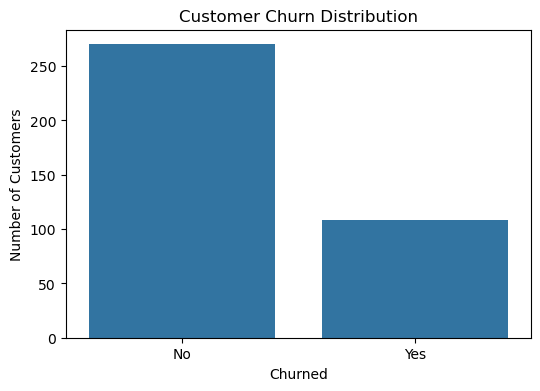

In [111]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=merge_data,
    x="churned"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churned")
plt.ylabel("Number of Customers")

plt.show()

## plot of categorical variable distribution

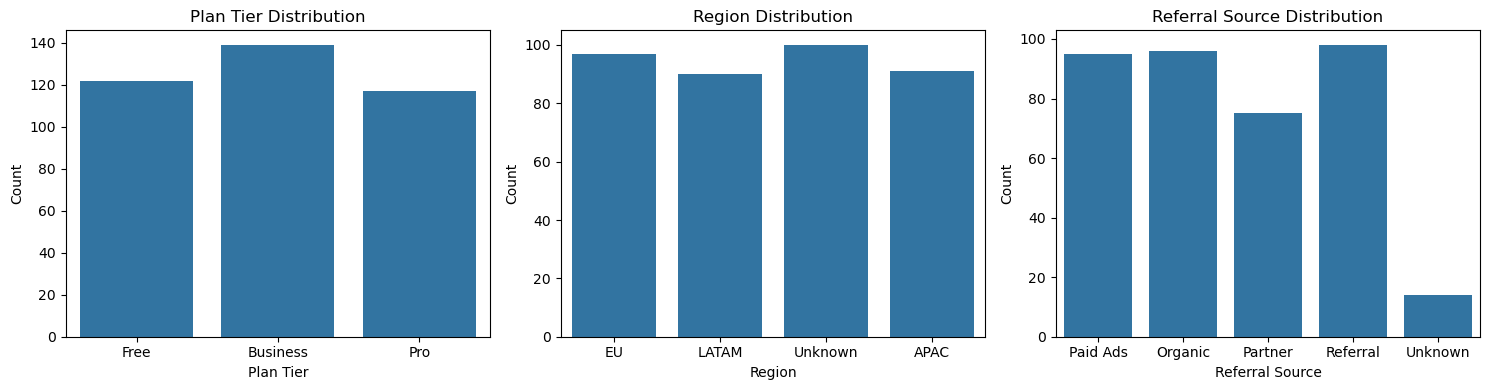

In [112]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(
    data=merge_data,
    x="plan_tier",
    ax=axes[0]
)

axes[0].set_title("Plan Tier Distribution")
axes[0].set_xlabel("Plan Tier")
axes[0].set_ylabel("Count")


sns.countplot(
    data=merge_data,
    x="region",
    ax=axes[1]
)

axes[1].set_title("Region Distribution")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Count")


sns.countplot(
    data=merge_data,
    x="referral_source",
    ax=axes[2]
)

axes[2].set_title("Referral Source Distribution")
axes[2].set_xlabel("Referral Source")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

## Numerical feature distribution

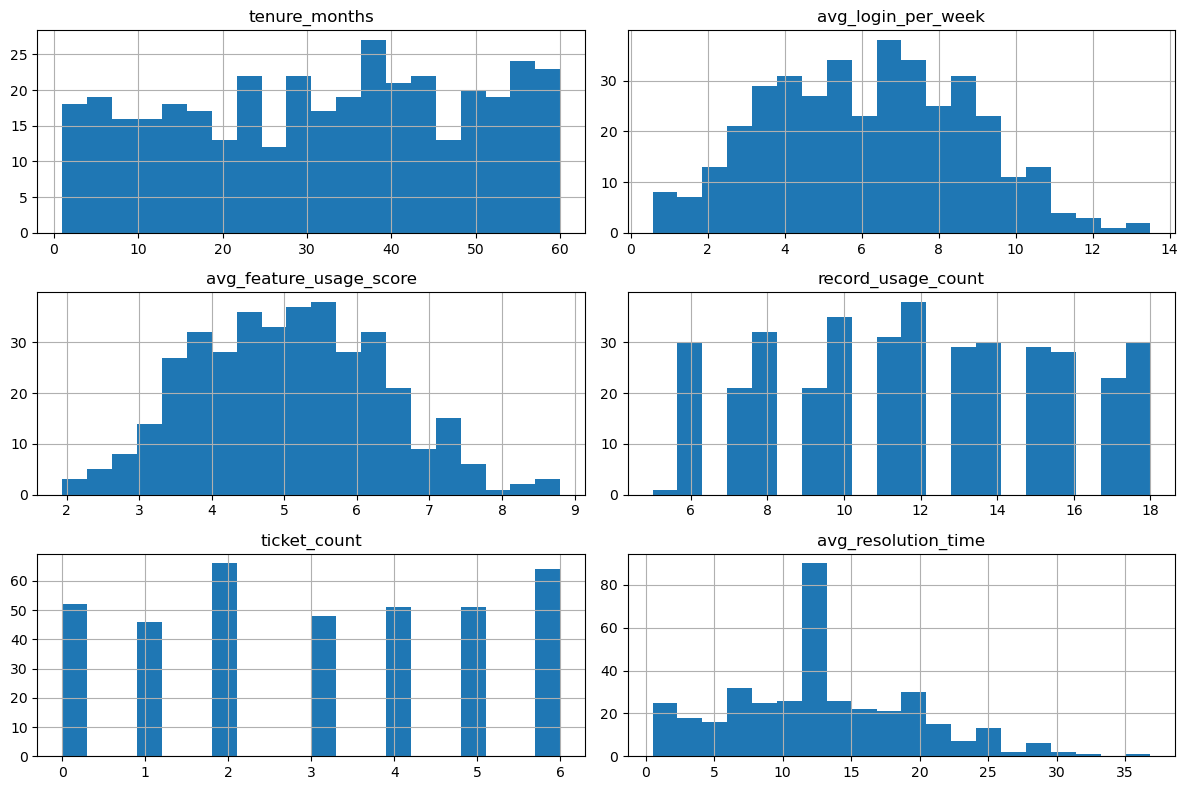

In [113]:
numeric_cols_eda = [
    "tenure_months",
    "avg_login_per_week",
    "avg_feature_usage_score",
    "record_usage_count",
    "ticket_count",
    "avg_resolution_time"
]

merge_data[numeric_cols_eda].hist(
    figsize=(12, 8),
    bins=20
)

plt.tight_layout()

plt.show()

## Separate X and y

In [114]:
X = merge_data.drop(columns=["account_id", "churned"])

y = merge_data["churned"]

In [115]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (378, 9)
y shape: (378,)


### check target 

In [116]:
print(y.value_counts())

print("\nPercentage:")
print(y.value_counts(normalize=True) * 100)

churned
No     270
Yes    108
Name: count, dtype: int64

Percentage:
churned
No     71.428571
Yes    28.571429
Name: proportion, dtype: float64


## Train/test split

In [117]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y #used to keep the same proportion of classes in both the training and testing datasets.
)

In [118]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train shape: (302, 9)
X_test shape: (76, 9)

Training target distribution:
churned
No     216
Yes     86
Name: count, dtype: int64

Testing target distribution:
churned
No     54
Yes    22
Name: count, dtype: int64


### Define categorical and numerical columns

In [119]:
categorical_cols = [
    "plan_tier",
    "region",
    "referral_source"
]

numeric_cols = [
    "tenure_months",
    "avg_login_per_week",
    "avg_feature_usage_score",
    "record_usage_count",
    "ticket_count",
    "avg_resolution_time"
]

In [120]:
print("Categorical columns:", categorical_cols)
print("Numerical columns:", numeric_cols)

Categorical columns: ['plan_tier', 'region', 'referral_source']
Numerical columns: ['tenure_months', 'avg_login_per_week', 'avg_feature_usage_score', 'record_usage_count', 'ticket_count', 'avg_resolution_time']


## Encode categorical column and scale numerical feature 

In [121]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", MinMaxScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)# handleunknown- Scikit-learn simply ignores the unseen category instead of producing an error
    ]
)

In [122]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [123]:
print("X_train shape:", X_train_processed.shape)
print("X_test shape:", X_test_processed.shape)

X_train shape: (302, 18)
X_test shape: (76, 18)


In [124]:
print(X_train_processed[:5])

[[0.54237288 0.53488176 0.59358361 0.84615385 1.         0.51219623
  0.         0.         1.         0.         0.         1.
  0.         1.         0.         0.         0.         0.        ]
 [0.44067797 0.34470252 0.28124198 0.07692308 0.66666667 0.0373771
  0.         1.         0.         0.         0.         1.
  0.         0.         0.         1.         0.         0.        ]
 [0.61016949 0.12014179 0.22941102 0.23076923 0.16666667 0.65998479
  0.         1.         0.         0.         1.         0.
  0.         0.         1.         0.         0.         0.        ]
 [0.69491525 0.54070842 0.58636557 0.15384615 1.         0.03854102
  1.         0.         0.         0.         0.         0.
  1.         1.         0.         0.         0.         0.        ]
 [0.55932203 0.53418631 0.57307996 0.92307692 0.16666667 0.53195749
  0.         1.         0.         0.         1.         0.
  0.         0.         0.         0.         1.         0.        ]]


In [125]:
feature_names = preprocessor.get_feature_names_out() #after preprocessing their column names

X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_train_df.head()

,num__tenure_months,num__avg_login_per_week,num__avg_feature_usage_score,num__record_usage_count,num__ticket_count,num__avg_resolution_time,cat__plan_tier_Business,cat__plan_tier_Free,cat__plan_tier_Pro,cat__region_APAC,cat__region_EU,cat__region_LATAM,cat__region_Unknown,cat__referral_source_Organic,cat__referral_source_Paid Ads,cat__referral_source_Partner,cat__referral_source_Referral,cat__referral_source_Unknown
278,0.542373,0.534882,0.593584,0.846154,1.000000,0.512196,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
226,0.440678,0.344703,0.281242,0.076923,0.666667,0.037377,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
70,0.610169,0.120142,0.229411,0.230769,0.166667,0.659985,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
45,0.694915,0.540708,0.586366,0.153846,1.000000,0.038541,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
325,0.559322,0.534186,0.573080,0.923077,0.166667,0.531957,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## Define Models

In [126]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "SVM": SVC(
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    )
}

print("Models:")
for name in models:
    print("-", name)

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- SVM


## Train and compare them

In [127]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score #How well the model separates churn vs non-churn
)

results = []

for name, model in models.items():

    # Train
    model.fit(X_train_processed, y_train)

    # Predict
    y_pred = model.predict(X_test_processed)

    # Churn probability
    y_prob = model.predict_proba(X_test_processed)[:, 1] # takes yes

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0 #to prevent an error or warning when precision/recall cannot be calculated normally
        ),
        "Recall": recall_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("F1", ascending=False))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.631579,0.411765,0.636364,0.500000,0.670875
3,SVM,0.565789,0.342857,0.545455,0.421053,0.546296
2,Random Forest,0.710526,0.500000,0.318182,0.388889,0.670034
1,Decision Tree,0.657895,0.388889,0.318182,0.350000,0.557239


## Hperparameter tuning

In [128]:
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10, 100]
    },

    "Decision Tree": {
        "max_depth": [2, 3, 5, 8, None],
        "min_samples_leaf": [1, 2, 5, 10],
        "criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 10, None],
        "min_samples_leaf": [1, 2, 5]
    },

    "SVM": {
        "C": [0.1, 1, 10],
        "gamma": ["scale", "auto"],
        "kernel": ["rbf", "linear"]
    }
}

In [129]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

f1_yes = make_scorer(
    f1_score,
    pos_label="Yes",
    zero_division=0
)

In [130]:
tuned_models = {}
tuning_results = {}

for name, model in models.items():

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring=f1_yes,
        cv=5,
        n_jobs=-1
    )

    grid.fit(X_train_processed, y_train)

    tuned_models[name] = grid.best_estimator_

    tuning_results[name] = {
        "Best Parameters": grid.best_params_,
        "Best CV F1": grid.best_score_
    }

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV F1:", grid.best_score_)


 Logistic Regression
Best Parameters: {'C': 10}
Best CV F1: 0.4980612883051907

 Decision Tree
Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 10}
Best CV F1: 0.5222912668559464

 Random Forest
Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}
Best CV F1: 0.5320002842478047

 SVM
Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'linear'}
Best CV F1: 0.46190969646726876


### Random Forest was selected because CV = 0.53.

## Final Test Evaluation

In [152]:
final_results = []

for name, model in tuned_models.items():

    # Predicting
    y_pred = model.predict(X_test_processed)

    # Probability of churn= Yes
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test,
            y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            y_pred,
            pos_label="Yes",
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })

final_results_df = pd.DataFrame(final_results)

final_results_df = final_results_df.sort_values(
    "F1",
    ascending=False
)

display(final_results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.644737,0.428571,0.681818,0.526316,0.691077
3,SVM,0.657895,0.437500,0.636364,0.518519,0.648569
0,Logistic Regression,0.631579,0.411765,0.636364,0.500000,0.676768
1,Decision Tree,0.578947,0.380952,0.727273,0.500000,0.687290


In [133]:
final_model = tuned_models["Random Forest"]

y_pred_final = final_model.predict(X_test_processed)

y_prob_final = final_model.predict_proba(
    X_test_processed
)[:, 1]

## Classification Report (RF)

In [135]:
print(classification_report(
    y_test,
    y_pred_final,
    labels=["No", "Yes"],
    zero_division=0
))

              precision    recall  f1-score   support

          No       0.83      0.63      0.72        54
         Yes       0.43      0.68      0.53        22

    accuracy                           0.64        76
   macro avg       0.63      0.66      0.62        76
weighted avg       0.71      0.64      0.66        76



## Confusion Matrix (RF)

In [134]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=["No", "Yes"]
)

print(cm)

[[34 20]
 [ 7 15]]


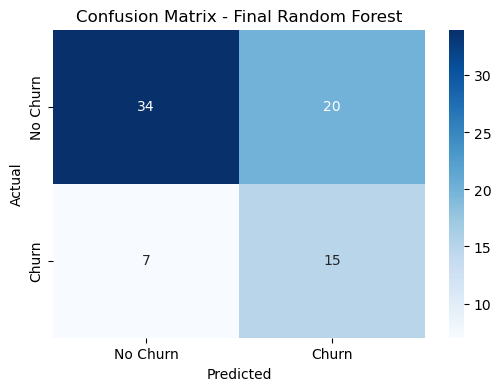

In [136]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Final Random Forest")

plt.show()

## Pickle the model (RF) and preprocessor

In [137]:
import pickle

# Select final model
final_model = tuned_models["Random Forest"]

# Save the final model
with open("final_churn_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

# Save the preprocessor
with open("churn_preprocessor.pkl", "wb") as file:
    pickle.dump(preprocessor, file)

print("Final model and preprocessor saved successfully.")

Final model and preprocessor saved successfully.


## FINAL PREDICTION DATASET

In [138]:
print(churned_to_predict.shape)
churned_to_predict.head()

(66, 1)


,account_id
0,CUST-0009
1,CUST-0014
2,CUST-0017
3,CUST-0038
4,CUST-0043


In [139]:
print(churned_to_predict.columns)

Index(['account_id'], dtype='object')


## Merge with account_master,usage_features,support_features

In [140]:
predict_data = churned_to_predict.merge(account_master,on="account_id",how="left")

print(predict_data.shape)
predict_data.head()

(66, 5)


,account_id,plan_tier,tenure_months,region,referral_source
0,CUST-0009,Pro,16,LATAM,Organic
1,CUST-0014,Free,8,NaN,Referral
2,CUST-0017,Pro,9,NaN,Referral
3,CUST-0038,Pro,15,APAC,Partner
4,CUST-0043,Pro,29,EU,Paid Ads


In [141]:
predict_data = predict_data.merge(usage_features,on="account_id",how="left")

In [142]:
predict_data = predict_data.merge(support_features,on="account_id",how="left")

In [143]:
predict_data

,account_id,plan_tier,tenure_months,region,referral_source,avg_login_per_week,avg_feature_usage_score,record_usage_count,ticket_count,avg_resolution_time
0,CUST-0009,Pro,16,LATAM,Organic,4.805488,4.348728,14,2.0,24.602690
1,CUST-0014,Free,8,NaN,Referral,3.068127,3.635212,15,6.0,19.747687
2,CUST-0017,Pro,9,NaN,Referral,6.949128,5.732479,6,4.0,7.345098
3,CUST-0038,Pro,15,APAC,Partner,1.433342,2.400478,6,5.0,6.371382
4,CUST-0043,Pro,29,EU,Paid Ads,8.087514,5.505429,7,4.0,13.334328
...,...,...,...,...,...,...,...,...,...,...
61,CUST-0400,Free,7,EU,Organic,11.293963,7.664032,7,6.0,20.439097
62,CUST-0408,Free,53,EU,Organic,7.889158,5.655287,16,2.0,1.162783
63,CUST-0411,Pro,30,EU,Paid Ads,7.690453,5.775419,16,1.0,5.162573
64,CUST-0417,Free,46,LATAM,Partner,6.100806,4.155597,15,5.0,6.114172


## Checking missing value & Handling 

In [144]:
predict_data.isnull().sum()

account_id                  0
plan_tier                   0
tenure_months               0
region                     16
referral_source             3
avg_login_per_week          0
avg_feature_usage_score     0
record_usage_count          0
ticket_count                9
avg_resolution_time         9
dtype: int64

In [145]:
predict_data["region"] = predict_data["region"].fillna("Unknown")
predict_data["referral_source"] = predict_data["referral_source"].fillna("Unknown")

In [146]:
predict_data["ticket_count"] = predict_data["ticket_count"].fillna(0)

In [147]:
predict_data["avg_resolution_time"] = predict_data["avg_resolution_time"].fillna(
    predict_data["avg_resolution_time"].median()
)

## after handling missing value

In [148]:
predict_data.isnull().sum()

account_id                 0
plan_tier                  0
tenure_months              0
region                     0
referral_source            0
avg_login_per_week         0
avg_feature_usage_score    0
record_usage_count         0
ticket_count               0
avg_resolution_time        0
dtype: int64

## Prepare prediction features

In [149]:
# Prepare prediction features
X_predict = predict_data[numeric_cols + categorical_cols]

# Apply the same preprocessing used during training
X_predict_processed = preprocessor.transform(X_predict)

# Use the tuned Random Forest
final_model = tuned_models["Random Forest"]

# Predict churn
y_predict = final_model.predict(X_predict_processed)

# Get probability of churn
y_probability = final_model.predict_proba(X_predict_processed)[:, 1]

# Create prediction dataframe
predictions = predict_data[["account_id"]].copy()
predictions["predicted_churn"] = y_predict
predictions["churn_probability"] = y_probability

predictions.head(10)

,account_id,predicted_churn,churn_probability
0,CUST-0009,Yes,0.646813
1,CUST-0014,Yes,0.565233
2,CUST-0017,No,0.323831
3,CUST-0038,Yes,0.706144
4,CUST-0043,No,0.312539
5,CUST-0048,No,0.452167
6,CUST-0055,No,0.252987
7,CUST-0059,Yes,0.641870
8,CUST-0060,No,0.381955
9,CUST-0063,No,0.281196


## Save file

In [151]:
predictions.to_csv("customer_churn_predictions.csv", index=False)
print("saved successfully!")

saved successfully!
